# HTM records: a tour

On the `feat/records-database` branch, HTM's database is built from YAML records in
`data/` instead of Python modules. This notebook shows what stays the same and what
the records add. See `docs/rfc/0001-data-records.md` for the design.

Install from a clone with `pip install -e ".[build]"`. The first import compiles `data/`
into a JSON file next to the package; later imports read it.

In [1]:
import h_transport_materials as htm
import numpy as np
import matplotlib.pyplot as plt

u = htm.ureg
print(len(htm.database), "properties")
for name in ["diffusivities", "solubilities", "permeabilities", "recombination_coeffs", "dissociation_coeffs"]:
    print(f"  {name:21s} {len(getattr(htm, name))}")

473 properties
  diffusivities         206
  solubilities          130
  permeabilities        94
  recombination_coeffs  25
  dissociation_coeffs   18


## The usual API keeps working

Filtering, values and plotting are unchanged, so existing scripts (FESTIM's included)
run as before.

In [2]:
W = htm.diffusivities.filter(material="tungsten", isotope="H")
print(len(W), "H diffusivities in tungsten\n")
for D in sorted(W, key=lambda p: p.year):
    print(f"{D.author:12s} {D.year}  D0 = {D.pre_exp:.2e~P}  E = {D.act_energy:.3f~P}")

12 H diffusivities in tungsten

moore        1964  D0 = 7.23×10⁻⁸ m²/s  E = 1.786 eV/particle
ryabchikov   1964  D0 = 8.10×10⁻⁶ m²/s  E = 0.859 eV/particle
frauenfelder 1969  D0 = 4.10×10⁻⁷ m²/s  E = 0.390 eV/particle
zakharov     1975  D0 = 6.06×10⁻⁴ m²/s  E = 1.066 eV/particle
esteban      2001  D0 = 5.68×10⁻¹⁰ m²/s  E = 0.096 eV/particle
heinola      2010  D0 = 5.20×10⁻⁸ m²/s  E = 0.210 eV/particle
johnson      2010  D0 = 6.32×10⁻⁷ m²/s  E = 0.390 eV/particle
liu          2014  D0 = 5.13×10⁻⁸ m²/s  E = 0.210 eV/particle
fernandez    2015  D0 = 1.93×10⁻⁷ m²/s  E = 0.200 eV/particle
holzner      2020  D0 = 2.06×10⁻⁷ m²/s  E = 0.280 eV/particle
zhou         2024  D0 = 1.88×10⁻⁷ m²/s  E = 0.201 eV/particle
zhou         2024  D0 = 1.93×10⁻⁷ m²/s  E = 0.201 eV/particle


2.6750332888774233e-09 meter ** 2 / second


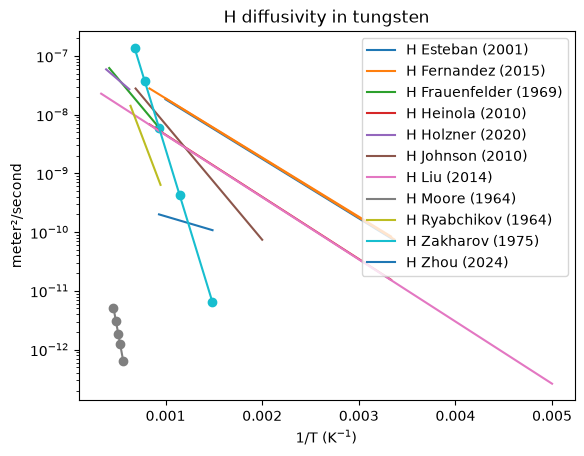

In [3]:
T = np.linspace(400, 1200, 50) * u.K
D = htm.get("htm:W-D-H-frauenfelder1969")
print(D.value(900 * u.K).to("m^2/s"))

htm.plotting.plot(W)
plt.yscale("log")
plt.title("H diffusivity in tungsten")
plt.show()

## Every property is a record with a permanent id

`htm.get(id)` returns the property; the full record is in `.record`. It keeps what the
paper printed (`reported`), what HTM did to it (`transformations`) and the normalised
values HTM computes from them.

In [4]:
S = htm.get("htm:W-S-H-frauenfelder1969")
rec = S.record
print("source:      ", rec["source"])
print("as printed:  ", rec["reported"]["pre_exp"], rec["reported"]["act_energy"])
print("transformed: ", [(t["op"], t["params"], t["origin"]) for t in rec["transformations"]])
print("normalised:  ", rec["normalized"]["pre_exp"])

source:       {'doi': '10.1116/1.1492699', 'key': 'frauenfelder1969', 'location': None, 'via': None}
as printed:   {'value': 0.29, 'unit': 'torr * L / cm^3 / torr^0.5', 'unit_as_printed': None} {'value': 24000.0, 'unit': 'cal/mol', 'unit_as_printed': None}
transformed:  [('gas_volume_to_amount', {'T_ref': '273 K'}, 'paper')]
normalised:   {'value': 8.883898300093707e+23, 'unit': 'particle / meter ** 3 / pascal ** 0.5'}


## HTM's own choices are labelled

Any step that is not in the paper is marked `origin: htm` and listed in
`htm_assumptions`, next to the value. Here, Heinola 2010 gives no temperature range: the
one HTM uses is its own.

In [5]:
H = htm.get("htm:W-D-H-heinola2010")
print("range in the paper:", H.record["reported"]["range"])
for a in H.record["htm_assumptions"]:
    print(f"HTM assumption ({a['op']}): {a['rationale'].strip()}")

n = sum(bool(p.record["htm_assumptions"]) for p in htm.database)
print(f"\n{n} of {len(htm.database)} records carry at least one HTM assumption")

range in the paper: None
HTM assumption (assume_range): The paper gives no temperature range for the fit. HTM uses 300 to 1200 K so the law can be plotted; this range is not the authors'.

174 of 473 records carry at least one HTM assumption


## Data points and the authors' fit

When a paper gives both data points and a fit, the record keeps both. The build fits the
points too and compares the two laws over the measured range; the authors' fit is used
unless they disagree by more than 10%, in which case a curator has to choose and say why.

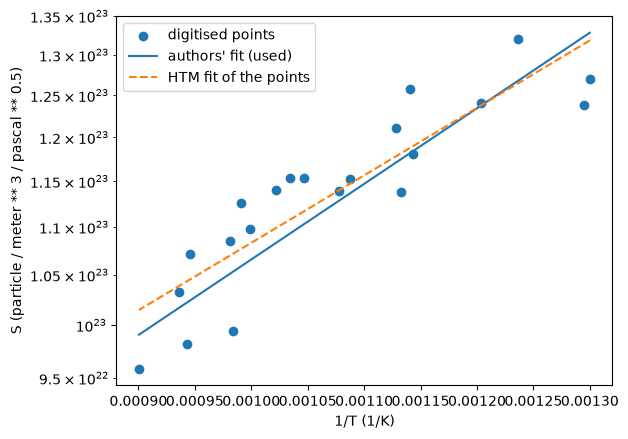

selected: author_fit | largest difference: 2.4%


In [6]:
S = htm.get("htm:Li50Pb50-S-H-schumacher1990")
n = S.record["normalized"]
T_pts = np.array(n["points"]["T"]["value"])
y_pts = np.array(n["points"]["y"]["value"])
T = np.linspace(T_pts.min(), T_pts.max(), 100)
kB = htm.k_B.m_as("eV/particle/K")

def law(fit):
    return fit["pre_exp"]["value"] * np.exp(-fit["act_energy"]["value"] / (kB * T))

plt.scatter(1 / T_pts, y_pts, label="digitised points")
plt.plot(1 / T, law(n["author_fit"]), label="authors' fit (used)")
plt.plot(1 / T, law(n["htm_refit"]), "--", label="HTM fit of the points")
plt.yscale("log")
plt.xlabel("1/T (1/K)")
plt.ylabel(f"S ({n['points']['y']['unit']})")
plt.legend()
plt.show()
print("selected:", n["selected"], "| largest difference:", f"{n['fit_discrepancy']['max_relative']:.1%}")

## Derived properties say where they come from

Some properties are not published but computed by HTM from other records, e.g. a
recombination coefficient from a dissociation coefficient and a solubility. They are
`derived` records that name their inputs.

In [7]:
Kr = htm.get("htm:SS304-Kr-H-grant1987")
rep = Kr.record["reported"]
print(" x ".join(f"{f['record']}^{f['power']:g}" for f in rep["factors"]))
print("origin:", rep["origin"], "-", rep["rationale"])

derived = [p.record_id for p in htm.database if p.record["reported"]["form"] == "derived"]
print(f"\n{len(derived)} derived records")

htm:SS304-Kd-H-grant1987^1 x htm:SS304-S-H-grant1987^-2
origin: htm - not given in the paper; HTM computes the recombination coefficient as Kd / S^2

14 derived records


## Curation status and open questions

Every record starts as a draft with flags for a verifier. Some are disputed: Fauvet 1988
prints a diffusivity in mm2/s that is only plausible in m2/s.

In [8]:
from collections import Counter

print(Counter(p.record["curation"]["status"] for p in htm.database))
F = htm.get("htm:LiPb-D-H-fauvet1988")
print("\n", F.record["reported"]["value"])
for flag in F.record["curation"]["flags"]:
    print(" -", flag.strip())

Counter({'draft': 472, 'disputed': 1})

 {'value': 1.5e-09, 'unit': 'm^2/s', 'unit_as_printed': 'mm2 s-1 (abstract)'}
 - The abstract prints 1.5e-9 mm2/s. HTM uses m2/s, which is consistent with other Pb-17Li diffusivities near 723 K (about 1e-9 m2/s). Check the body of the paper and record the location of the value used.


## Comparison with the legacy Python database

`htm.legacy_database()` still loads the old modules. Every record maps to the property
it replaces (`data/migration/legacy.yaml`); the values agree except for documented
corrections (single temperatures instead of fake ranges, the Schumacher author fit, a
sample composition, cited densities instead of derived ones).

In [9]:
import yaml

with open("data/migration/legacy.yaml") as f:
    manifest = yaml.safe_load(f)
legacy = htm.legacy_database()
by_id = {p.record_id: p for p in htm.database}

diffs = []
for record_id, entry in manifest.items():
    new, old = by_id[record_id], legacy[entry["index"]]
    T = 0.5 * sum(t.m_as("K") for t in old.range) * u.K
    diffs.append((abs((new.value(T) / old.value(T)).m_as("") - 1), record_id))

diffs.sort(reverse=True)
print(f"{sum(d < 1e-9 for d, _ in diffs)} of {len(diffs)} identical at the middle of their range")
for d, record_id in diffs[:6]:
    print(f"  {d:8.2e}  {record_id}")

462 of 473 identical at the middle of their range
  1.48e-02  htm:LiPb-S-H-candido2022-b
  1.48e-02  htm:LiPb-S-H-candido2022
  1.11e-02  htm:Li50Pb50-S-H-schumacher1990
  1.44e-04  htm:Li-S-T-smith1979
  1.44e-04  htm:Li-S-D-smith1979
  1.44e-04  htm:Li-S-H-smith1979


## The records themselves

Each record is a small YAML file under `data/records/`, with sources and materials in
their own folders. Contributors edit these, not Python.

In [10]:
print(open("data/records/W-S-H-frauenfelder1969.yaml").read())

id: htm:W-S-H-frauenfelder1969
property: solubility
law: sieverts
material: tungsten
isotope: H
method: unknown
source:
  doi: 10.1116/1.1492699
  location: null
reported:
  form: arrhenius
  pre_exp:
    value: 2.9e-1
    unit: "torr * L / cm^3 / torr^0.5"
  act_energy: {value: 24000, unit: "cal/mol"}
  range: {value: [1100, 2400], unit: K}
transformations:
  - op: gas_volume_to_amount
    params: {T_ref: "273 K"}
    origin: paper
    rationale: the paper gives the dissolved amount as a gas volume (torr L) at 273 K
curation:
  status: draft
  flags:
    - fill method and location from the paper
    - check that 273 K (not 273.15 K) is the reference temperature printed

